### Clasificación

| Tipo | Descripción | Ejemplo en Saber 11 |
|---|---|---|
| **Nominal** | Categorías sin orden — ninguna categoría es "mayor" que otra | Sexo de la víctima, Estado Civil, País de Nacimiento, Pertenencia Grupal, Pertenencia Étnica, Código DANE Municipio, Municipio del hecho DANE, Departamento del hecho DANE, Código DANE Departamento, Escenario del Hecho, Zona del Hecho, Actividad Durante el Hecho, Circunstancia del Hecho Detallada, Manera de muerte, Mecanismo Causal de la Lesión Fatal, Diagnóstico Topográfico de la Lesión Fatal, Presunto Agresor Detallado, Localidad del Hecho, Ancestro Racial, Pueblo Indígena, Orientación Sexual, Identidad de Género, Transgénero. |
| **Ordinal** | Categorías con orden — hay una jerarquía natural entre categorías | Grupo de edad quinquenal, Grupo Mayor Menor de Edad, Grupo de Edad judicial, Ciclo Vital, Escolaridad, Mes del hecho, Rango de Hora del Hecho X 3 Horas. |
| **Discreta** | Números enteros contables — no pueden tomar valores intermedios | Año del hecho |

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

# Cargar el archivo de homicidios
df = pd.read_csv("../Presuntos_Homicidios._Colombia,_2015_a_2024._Cifras_definitivas_20260916.csv", encoding="utf-8")

print("Datos cargados correctamente.")
print("Dimensiones del dataset:", df.shape)

# Mostrar los primeros registros
display(df.head())


Datos cargados correctamente.
Dimensiones del dataset: (125284, 33)


,ID,Año del hecho,Grupo de edad quinquenal,Grupo Mayor Menor de Edad,Grupo de Edad judicial,Ciclo Vital,Sexo de la victima,Estado Civil,País de Nacimiento,Escolaridad,...,Manera de muerte,Mecanismo Causal de la Lesión Fatal,Diagnostico Topográfico de la Lesión Fatal,Presunto Agresor Detallado,Localidad del Hecho,Ancestro Racial,Pueblo Indígena,Orientación Sexual,Identidad de Género,Transgénero
0,1,2015,(20 a 24),b) Mayor de Edad (>18 Años),(20 a 24),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica primaria,...,1 Presuntos Homicidios,Corto punzante,Trauma de abdomen,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
1,2,2015,(25 a 29),b) Mayor de Edad (>18 Años),(25 a 28),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica primaria,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Trauma craneano,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
2,3,2015,(20 a 24),b) Mayor de Edad (>18 Años),(20 a 24),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica secundaria,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Trauma craneano,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
3,4,2015,(30 a 34),b) Mayor de Edad (>18 Años),(29 a 34),(29 a 59) Adultez,Mujer,Soltero(a),Colombia,Preescolar,...,1 Presuntos Homicidios,Corto punzante,Trauma de cuello,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
4,5,2015,(25 a 29),b) Mayor de Edad (>18 Años),(25 a 28),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Preescolar,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Politraumatismo,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada


In [4]:

# Convertir a mayúsculas y eliminar espacios en columnas de texto
columnas_texto = df.select_dtypes(include=["object", "string"]).columns

df[columnas_texto] = df[columnas_texto].apply(
    lambda columna: columna.str.strip().str.upper()
)

print("¡Estandarización de texto realizada exitosamente!")


¡Estandarización de texto realizada exitosamente!


HISTOGRAMA

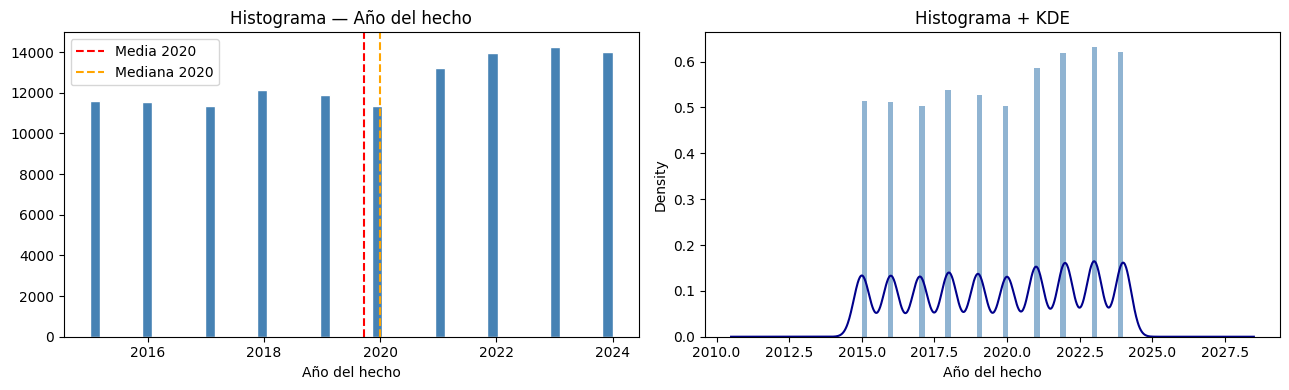

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["Año del hecho"].dropna(), bins=50, color="steelblue", edgecolor="white")
axes[0].axvline(df["Año del hecho"].mean(),   color="red",    linestyle="--", label=f"Media {df['Año del hecho'].mean():.0f}")
axes[0].axvline(df["Año del hecho"].median(), color="orange", linestyle="--", label=f"Mediana {df['Año del hecho'].median():.0f}")
axes[0].set_title("Histograma — Año del hecho"); axes[0].set_xlabel("Año del hecho"); axes[0].legend()

df["Año del hecho"].dropna().plot.hist(bins=50, density=True, alpha=0.6, ax=axes[1], color="steelblue")
df["Año del hecho"].dropna().plot.kde(ax=axes[1], color="darkblue")
axes[1].set_title("Histograma + KDE"); axes[1].set_xlabel("Año del hecho")

plt.tight_layout(); plt.show()

 La distribución permite identificar los periodos con mayor representación de casos en el dataset. Esta información ayuda a reconocer cambios temporales y a determinar qué años requieren un análisis más detallado.

BOXPLOT

C:\Users\Usuario\AppData\Local\Temp\ipykernel_24088\591022689.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(grupos, labels=[str(anio) for anio in anios])


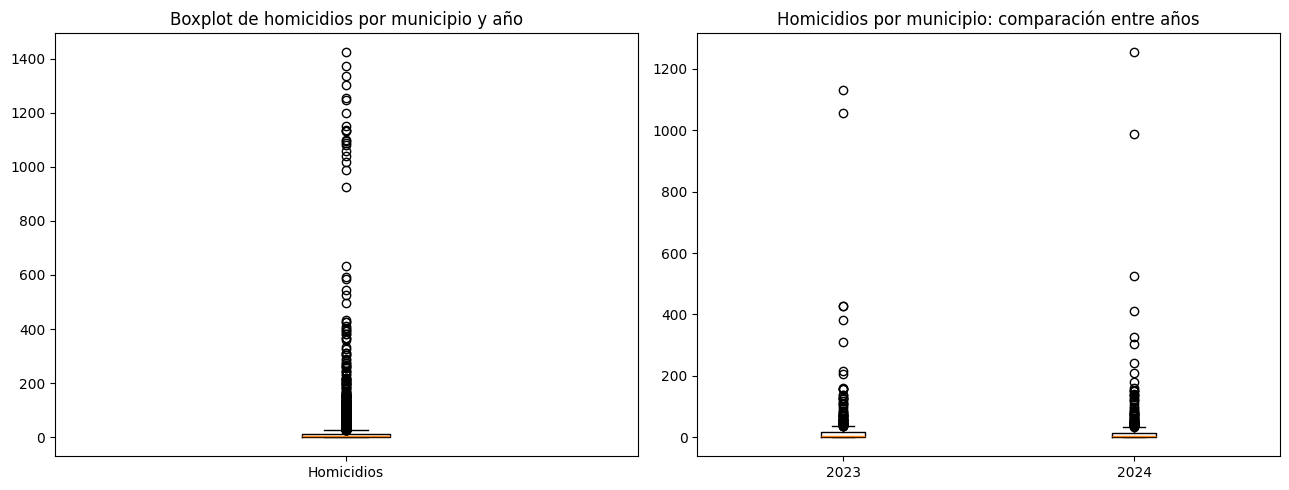

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

conteos = df.groupby(["Año del hecho", "Municipio del hecho DANE"]).size().reset_index(name="Homicidios")

axes[0].boxplot(conteos["Homicidios"].dropna())
axes[0].set_title("Boxplot de homicidios por municipio y año"); axes[0].set_xticklabels(["Homicidios"])

anios = conteos.groupby("Año del hecho")["Homicidios"].sum().nlargest(2).index.tolist()
grupos = [conteos[conteos["Año del hecho"] == anio]["Homicidios"].dropna() for anio in anios]
axes[1].boxplot(grupos, labels=[str(anio) for anio in anios])
axes[1].set_title("Homicidios por municipio: comparación entre años")

plt.tight_layout(); plt.show()

C:\Users\Usuario\AppData\Local\Temp\ipykernel_24088\2493354544.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(grupos, labels=[str(anio) for anio in anios])


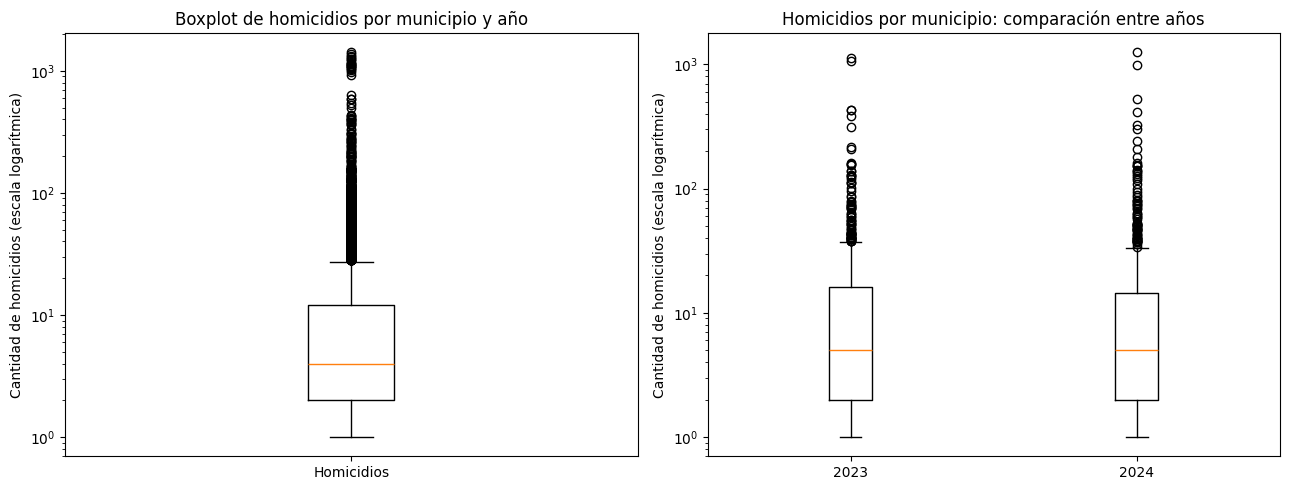

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

conteos = df.groupby(
    ["Año del hecho", "Municipio del hecho DANE"]
).size().reset_index(name="Homicidios")

axes[0].boxplot(conteos["Homicidios"].dropna())
axes[0].set_yscale("log")
axes[0].set_title("Boxplot de homicidios por municipio y año")
axes[0].set_xticklabels(["Homicidios"])
axes[0].set_ylabel("Cantidad de homicidios (escala logarítmica)")

anios = sorted(conteos["Año del hecho"].dropna().unique())[-2:]

grupos = [
    conteos[conteos["Año del hecho"] == anio]["Homicidios"].dropna()
    for anio in anios
]

axes[1].boxplot(grupos, labels=[str(anio) for anio in anios])
axes[1].set_yscale("log")
axes[1].set_title("Homicidios por municipio: comparación entre años")
axes[1].set_ylabel("Cantidad de homicidios (escala logarítmica)")

plt.tight_layout()
plt.show()


El gráfico permite comparar la dispersión de los casos entre municipios y podemos detectar que hay muchos valores "atipicos". Estos valores pueden orientar una revisión territorial más detallada, aunque no necesariamente representan errores ya que debido al contexto territorial estos pueden ser valores legitimos.

HEADMAP

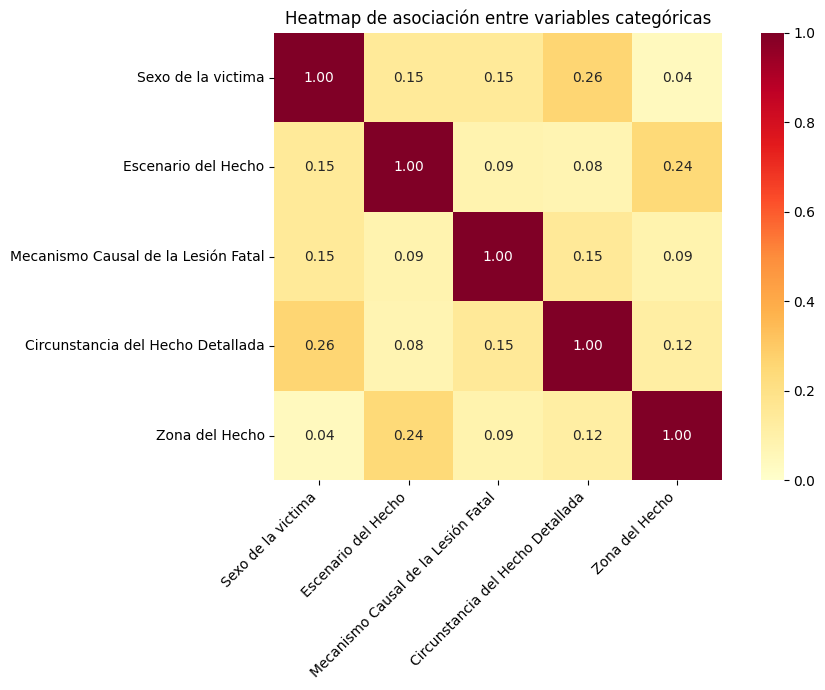

In [9]:

from scipy.stats import chi2_contingency

VARIABLES = [
    "Sexo de la victima",
    "Escenario del Hecho",
    "Mecanismo Causal de la Lesión Fatal",
    "Circunstancia del Hecho Detallada",
    "Zona del Hecho"
]

def cramers_v(x, y):
    tabla = pd.crosstab(x, y)

    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return np.nan

    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    r, k = tabla.shape

    return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

matriz = pd.DataFrame(index=VARIABLES, columns=VARIABLES, dtype=float)

for var1 in VARIABLES:
    for var2 in VARIABLES:
        matriz.loc[var1, var2] = cramers_v(df[var1], df[var2])

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    square=True
)

plt.title("Heatmap de asociación entre variables categóricas")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


La matriz permite explorar qué características categóricas presentan mayor asociación. Los resultados deben interpretarse con precaución ya que descrubimos que variables como "circunstancia del hecho detallada" presenta muchos valores no resgistrados.

TABLA PIVOTE

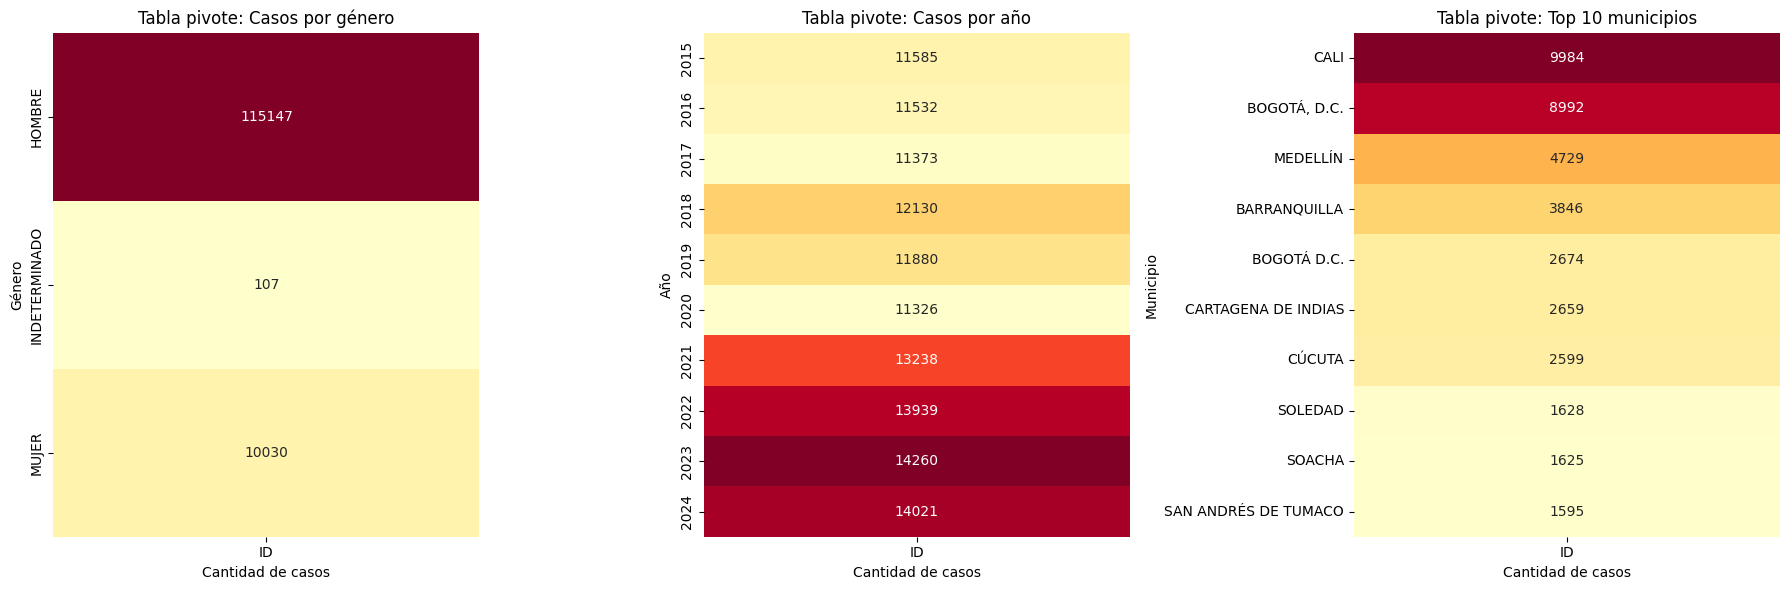

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Tabla pivote: casos por género
pivot_genero = df.pivot_table(
    values="ID",
    index="Sexo de la victima",
    aggfunc="count"
)

sns.heatmap(
    pivot_genero,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    ax=axes[0],
    cbar=False
)
axes[0].set_title("Tabla pivote: Casos por género")
axes[0].set_xlabel("Cantidad de casos")
axes[0].set_ylabel("Género")

# 2. Tabla pivote: casos por año
pivot_anio = df.pivot_table(
    values="ID",
    index="Año del hecho",
    aggfunc="count"
).sort_index()

sns.heatmap(
    pivot_anio,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    ax=axes[1],
    cbar=False
)
axes[1].set_title("Tabla pivote: Casos por año")
axes[1].set_xlabel("Cantidad de casos")
axes[1].set_ylabel("Año")

# 3. Tabla pivote: top 10 municipios
pivot_municipio = df.pivot_table(
    values="ID",
    index="Municipio del hecho DANE",
    aggfunc="count"
).sort_values(
    by="ID",
    ascending=False
).head(10)

sns.heatmap(
    pivot_municipio,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    ax=axes[2],
    cbar=False
)
axes[2].set_title("Tabla pivote: Top 10 municipios")
axes[2].set_xlabel("Cantidad de casos")
axes[2].set_ylabel("Municipio")

plt.tight_layout()
plt.show()

GRAFICOS DE BARRAS

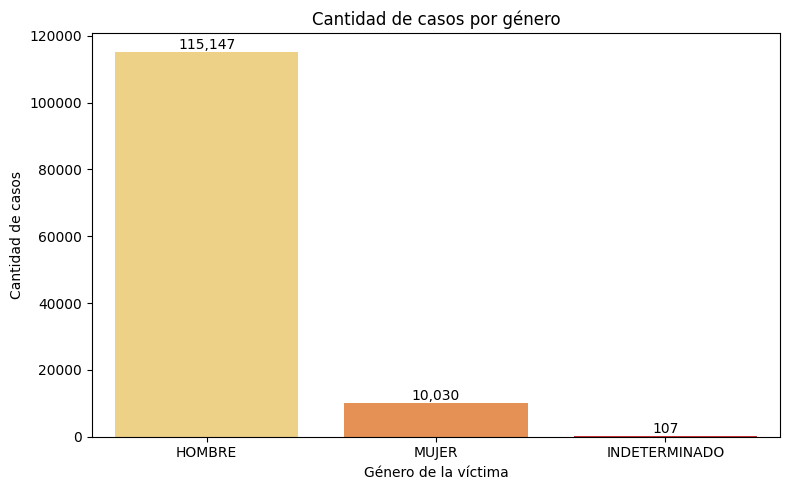

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

conteo_genero = df["Sexo de la victima"].value_counts()

sns.barplot(
    x=conteo_genero.index,
    y=conteo_genero.values,
    hue=conteo_genero.index,
    palette="YlOrRd",
    legend=False,
    ax=ax
)

ax.set_title("Cantidad de casos por género")
ax.set_xlabel("Género de la víctima")
ax.set_ylabel("Cantidad de casos")

for i, valor in enumerate(conteo_genero.values):
    ax.text(i, valor, f"{valor:,.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

El gráfico muestra cómo se distribuyen los registros según el sexo de la víctima. Esta comparación permite identificar diferencias en el número de casos registrados y como podemos ver gran parte de estos suceden a los hombres.

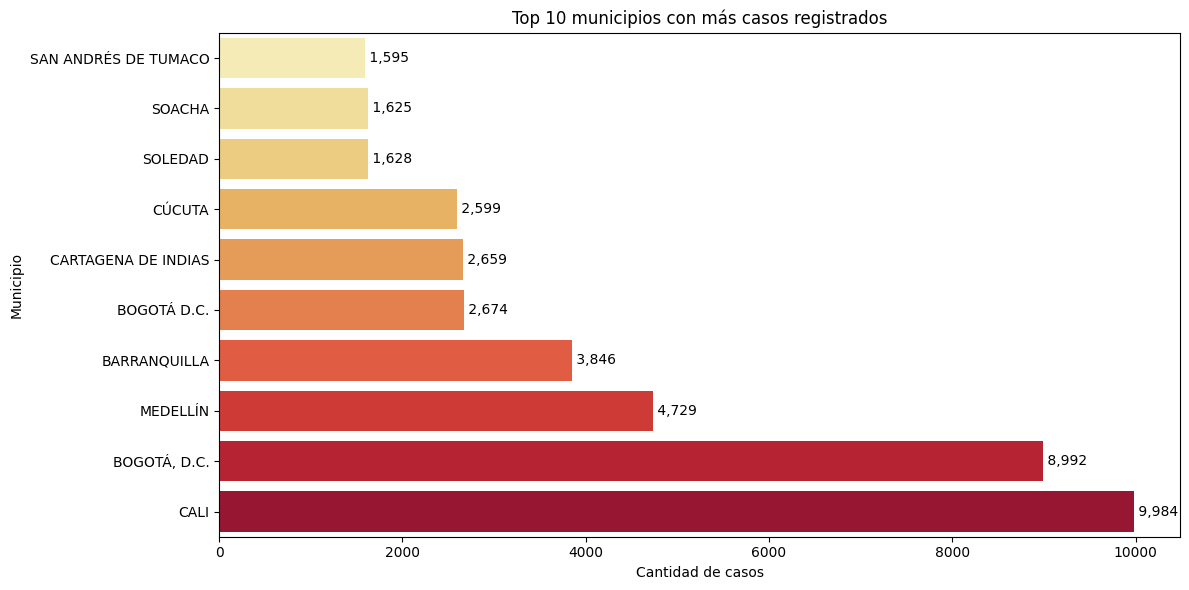

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))

conteo_municipio = (
    df["Municipio del hecho DANE"]
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

sns.barplot(
    x=conteo_municipio.values,
    y=conteo_municipio.index,
    hue=conteo_municipio.index,
    palette="YlOrRd",
    legend=False,
    ax=ax
)

ax.set_title("Top 10 municipios con más casos registrados")
ax.set_xlabel("Cantidad de casos")
ax.set_ylabel("Municipio")

for i, valor in enumerate(conteo_municipio.values):
    ax.text(valor, i, f" {valor:,.0f}", va="center")

plt.tight_layout()
plt.show()

El gráfico identifica los diez municipios con mayor número de registros en el dataset. Esta información puede ayudar a priorizar análisis territoriales.